In [2]:
# библиотеки и параметры, общие для обеих задач
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

SEED = 42
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
METRICS = {"classification": ["F1_macro", "Accuracy"], "regression": ["MAE", "RMSE", "R2"]}
PRIMARY = {"classification": "F1_macro", "regression": "MAE"}
VARIANTS = ["dummy", "sklearn", "sklearn+", "own", "own+"]

In [3]:
# читаем исходные таблицы из архивов UCI и явно отделяем цели от признаков
def read_uci_file(archive_name, filename, **read_options):
    url = f"https://archive.ics.uci.edu/static/public/{archive_name}"
    with urlopen(url, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        member = next(name for name in archive.namelist() if Path(name).name == filename)
        with archive.open(member) as source:
            return pd.read_csv(source, header=None, **read_options)


wifi_columns = [f"signal_{i}" for i in range(1, 8)] + ["room"]
wifi = read_uci_file(
    "422/wireless+indoor+localization.zip", "wifi_localization.txt",
    sep=r"\s+", names=wifi_columns,
)

hardware_features = ["MYCT", "MMIN", "MMAX", "CACH", "CHMIN", "CHMAX"]
hardware_columns = ["vendor", "model", *hardware_features, "PRP", "ERP"]
hardware = read_uci_file(
    "29/computer+hardware.zip", "machine.data", names=hardware_columns,
)

assert wifi.shape == (2000, 8) and hardware.shape == (209, 10)
assert set(wifi["room"]) == {1, 2, 3, 4}
assert not wifi.isna().any().any() and not hardware.isna().any().any()

DATA = {
    "classification": (wifi[wifi_columns[:-1]].to_numpy(dtype=float), wifi["room"].to_numpy()),
    "regression": (hardware[hardware_features].to_numpy(dtype=float), hardware["PRP"].to_numpy(dtype=float)),
}
for task, (X, y) in DATA.items():
    print(f"{TASK_NAMES[task]}: {X.shape[0]} объектов, {X.shape[1]} признаков")

Классификация: 2000 объектов, 7 признаков
Регрессия: 209 объектов, 6 признаков


In [4]:
# преобразуем признаки внутри каждого разбиения и считаем метрики
def transform_features(X_train, X_eval, preparation):
    if preparation == "relative":
        X_train = np.column_stack([X_train, X_train - X_train.max(axis=1, keepdims=True)])
        X_eval = np.column_stack([X_eval, X_eval - X_eval.max(axis=1, keepdims=True)])
    elif preparation == "ratios":
        def with_ratios(X):
            memory_growth = X[:, 2] / np.maximum(X[:, 1], 1)
            cache_share = X[:, 3] / np.maximum(X[:, 2], 1)
            return np.column_stack([X, memory_growth, cache_share])

        X_train, X_eval = with_ratios(X_train), with_ratios(X_eval)
    elif preparation == "log":
        X_train, X_eval = np.log1p(X_train), np.log1p(X_eval)

    if preparation in {"scale", "log", "relative"}:
        scaler = StandardScaler().fit(X_train)
        X_train, X_eval = scaler.transform(X_train), scaler.transform(X_eval)
    return X_train, X_eval


def folds(task, X, y, n_splits, seed):
    splitter_class = StratifiedKFold if task == "classification" else KFold
    return splitter_class(n_splits=n_splits, shuffle=True, random_state=seed).split(X, y)


def predict_on(model, preparation, X_train, y_train, X_eval):
    X_train, X_eval = transform_features(X_train, X_eval, preparation)
    return model.fit(X_train, y_train).predict(X_eval)


def scores(task, y, prediction):
    if task == "classification":
        return {
            "F1_macro": f1_score(y, prediction, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, prediction),
        }
    return {
        "MAE": mean_absolute_error(y, prediction),
        "RMSE": np.sqrt(mean_squared_error(y, prediction)),
        "R2": r2_score(y, prediction),
    }

## Модели

Ограничение глубины и размера листа может снизить переобучение. Для Wi-Fi добавляем отступы от сильнейшего сигнала, для PRP - соотношения объёмов памяти

In [5]:
# строим CART по снижению примеси Джини или суммы квадратов ошибок
from dataclasses import dataclass


@dataclass
class Node:
    value: float
    feature: int = -1
    threshold: float = 0.0
    left: object = None
    right: object = None


class CART:
    def __init__(self, task, max_depth=None, min_samples_leaf=1, max_features=None, seed=SEED):
        self.task = task
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.seed = seed

    def fit(self, X, y):
        self.X, self.y = X, y
        self.rng = np.random.default_rng(self.seed)
        if self.task == "classification":
            self.classes, encoded = np.unique(y, return_inverse=True)
            self.targets = np.eye(len(self.classes))[encoded]
        else:
            self.targets = y.reshape(-1, 1)
        self.root = self._grow(np.arange(len(y)), depth=0)
        return self

    def _grow(self, indices, depth):
        count = len(indices)
        targets = self.targets[indices]
        totals = targets.sum(axis=0)
        value = self.classes[totals.argmax()] if self.task == "classification" else totals[0] / count
        node = Node(value)
        min_leaf = self.min_samples_leaf
        if count < 2 * min_leaf or (self.max_depth is not None and depth >= self.max_depth):
            return node
        if np.all(self.y[indices] == self.y[indices[0]]):
            return node

        feature_count = self.X.shape[1]
        features = np.arange(feature_count)
        if self.max_features == "sqrt":
            features = self.rng.permutation(features)[:max(1, int(np.sqrt(feature_count)))]

        parent_quality = np.dot(totals, totals) / count
        best_quality = parent_quality + 1e-12
        best_split = None
        for feature in features:
            order = np.argsort(self.X[indices, feature], kind="stable")
            sorted_indices = indices[order]
            values = self.X[sorted_indices, feature]
            cuts = np.flatnonzero(values[1:] > values[:-1]) + 1
            cuts = cuts[(cuts >= min_leaf) & (cuts <= count - min_leaf)]
            if not len(cuts):
                continue
            left_totals = targets[order].cumsum(axis=0)[cuts - 1]
            right_totals = totals - left_totals
            quality = (left_totals ** 2).sum(axis=1) / cuts
            quality += (right_totals ** 2).sum(axis=1) / (count - cuts)
            best = quality.argmax()
            if quality[best] > best_quality:
                cut = cuts[best]
                best_quality = quality[best]
                threshold = values[cut - 1] + (values[cut] - values[cut - 1]) / 2
                best_split = feature, threshold, sorted_indices[:cut], sorted_indices[cut:]

        if best_split is not None:
            node.feature, node.threshold, left, right = best_split
            node.left = self._grow(left, depth + 1)
            node.right = self._grow(right, depth + 1)
        return node

    def predict(self, X):
        predictions = []
        for row in X:
            node = self.root
            while node.feature >= 0:
                node = node.left if row[node.feature] <= node.threshold else node.right
            predictions.append(node.value)
        return np.asarray(predictions)

In [6]:
# подключаем два варианта дерева с одинаковыми ограничениями глубины и листьев
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


def library_model(task, **params):
    estimator = DecisionTreeClassifier if task == "classification" else DecisionTreeRegressor
    return estimator(random_state=SEED, **params)


def own_model(task, **params):
    return CART(task, **params)

In [7]:
# проверяем глубину и размер листа независимо друг от друга
from itertools import product

LAB = 3
base = {"max_depth": None, "min_samples_leaf": 1}
classification_shallow = {"max_depth": 8, "min_samples_leaf": 4}
CONFIGS = {
    "classification": {
        "base": ("raw", base),
        "relative": ("relative", base),
        "shallow": ("raw", classification_shallow),
        "relative_shallow": ("relative", classification_shallow),
    },
    "regression": {"base": ("raw", base)},
}

for preparation, depth, min_leaf in product(
    ("raw", "ratios"), (None, 3, 5, 8), (1, 2, 3),
):
    params = {"max_depth": depth, "min_samples_leaf": min_leaf}
    name = "base" if preparation == "raw" and params == base else f"{preparation}_depth_{depth}_leaf_{min_leaf}"
    CONFIGS["regression"][name] = (preparation, params)

## Эксперимент

Сравниваем Dummy, исходные модели (sklearn и own) и те же модели с настройками, выбранными на внутренних фолдах (sklearn+ и own+).
В регрессии проверяем 24 сочетания признаков, глубины и размера листа.
Таблица обучения и проверки помогает оценить переобучение. В парных сравнениях положительное Delta означает улучшение

In [8]:
# на каждом внешнем фолде выбираем настройки только по внутренней кросс-валидации
def choose_candidate(task, X_train, y_train, seed):
    variants = CONFIGS[task]
    inner_folds = list(folds(task, X_train, y_train, n_splits=3, seed=seed))
    means = {}
    for name, (preparation, params) in variants.items():
        values = []
        for train, valid in inner_folds:
            prediction = predict_on(
                library_model(task, **params), preparation,
                X_train[train], y_train[train], X_train[valid],
            )
            values.append(scores(task, y_train[valid], prediction)[PRIMARY[task]])
        means[name] = float(np.mean(values))
    select_best = max if task == "classification" else min
    return select_best(means, key=means.get), means


def run_experiments():
    rows, search_rows = [], []
    for task, (X, y) in DATA.items():
        for fold, (train, test) in enumerate(folds(task, X, y, n_splits=5, seed=SEED), start=1):
            X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]
            selected, means = choose_candidate(task, X_train, y_train, SEED + fold)
            search_rows.extend(
                {"task": task, "fold": fold, "candidate": name, "score": score, "selected": name == selected}
                for name, score in means.items()
            )

            baseline_prep, baseline_params = CONFIGS[task]["base"]
            selected_prep, selected_params = CONFIGS[task][selected]
            dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
            experiments = {
                "dummy": (dummy, "raw"),
                "sklearn": (library_model(task, **baseline_params), baseline_prep),
                "sklearn+": (library_model(task, **selected_params), selected_prep),
                "own": (own_model(task, **baseline_params), baseline_prep),
                "own+": (own_model(task, **selected_params), selected_prep),
            }
            for variant, (model, preparation) in experiments.items():
                prepared_train, prepared_test = transform_features(X_train, X_test, preparation)
                model.fit(prepared_train, y_train)
                metrics = scores(task, y_test, model.predict(prepared_test))
                train_metrics = {
                    f"train_{name}": value
                    for name, value in scores(task, y_train, model.predict(prepared_train)).items()
                }
                rows.append({"lab": LAB, "task": task, "fold": fold, "variant": variant,
                             "candidate": selected if variant.endswith("+") else "base",
                             **metrics, **train_metrics})
            print(f"{TASK_NAMES[task]} - фолд {fold}/5 - настройки {selected}", flush=True)
    return pd.DataFrame(rows), pd.DataFrame(search_rows)

In [9]:
# запускаем эксперимент, показываем результаты гипотез и сохраняем оценки по фолдам
results, search = run_experiments()
for task in TASK_NAMES:
    print(f"\n{TASK_NAMES[task]} - внутренний поиск по {PRIMARY[task]}")
    selection = search.loc[search["task"] == task].groupby("candidate").agg(
        cv_mean=("score", "mean"), cv_std=("score", "std"), selected_folds=("selected", "sum"),
    )
    display(selection.sort_values("cv_mean", ascending=task == "regression").round(4))

    print("Внешняя кросс-валидация - среднее и стандартное отклонение")
    report = results.loc[results["task"] == task].groupby("variant")[METRICS[task]].agg(["mean", "std"])
    display(report.reindex(VARIANTS).round(4))

    print("Средняя метрика на обучении и внешних фолдах")
    metric = PRIMARY[task]
    fit_report = results.loc[results["task"] == task].groupby("variant")[[f"train_{metric}", metric]].mean()
    display(fit_report.reindex(VARIANTS).round(4))

output = Path("results") / f"lab_{LAB:02d}.csv"
output.parent.mkdir(exist_ok=True)
results.to_csv(output, index=False)
print(f"Файл для итогового сравнения: {output}")

Классификация - фолд 1/5 - настройки base
Классификация - фолд 2/5 - настройки base
Классификация - фолд 3/5 - настройки relative_shallow
Классификация - фолд 4/5 - настройки relative_shallow
Классификация - фолд 5/5 - настройки relative_shallow
Регрессия - фолд 1/5 - настройки raw_depth_5_leaf_3
Регрессия - фолд 2/5 - настройки raw_depth_8_leaf_1
Регрессия - фолд 3/5 - настройки raw_depth_8_leaf_1
Регрессия - фолд 4/5 - настройки raw_depth_8_leaf_3
Регрессия - фолд 5/5 - настройки raw_depth_5_leaf_3

Классификация - внутренний поиск по F1_macro


,cv_mean,cv_std,selected_folds
candidate,,,
base,0.9689,0.0052,2
relative,0.9668,0.0031,0
relative_shallow,0.9661,0.0056,3
shallow,0.9656,0.0034,0


Внешняя кросс-валидация - среднее и стандартное отклонение


F1_macro         Accuracy        
             mean     std     mean     std
variant                                   
dummy      0.1000  0.0000   0.2500  0.0000
sklearn    0.9651  0.0127   0.9650  0.0127
sklearn+   0.9676  0.0108   0.9675  0.0109
own        0.9635  0.0122   0.9635  0.0122
own+       0.9685  0.0074   0.9685  0.0074

Средняя метрика на обучении и внешних фолдах


,train_F1_macro,F1_macro
variant,,
dummy,0.1000,0.1000
sklearn,1.0000,0.9651
sklearn+,0.9916,0.9676
own,1.0000,0.9635
own+,0.9916,0.9685


... (3 outputs left out)

MAE               RMSE               R2        
             mean      std      mean      std    mean     std
variant                                                      
dummy     78.3256  21.2535  160.4872  63.1679 -0.1438  0.0294
sklearn   32.2402   9.4931   56.9003  25.1522  0.8469  0.0725
sklearn+  34.6620  12.0737   65.4792  35.2562  0.7934  0.1277
own       33.4754   9.1672   58.5474  24.1532  0.8361  0.0724
own+      34.5636  12.5960   65.5861  35.5274  0.7958  0.1278

Средняя метрика на обучении и внешних фолдах


,train_MAE,MAE
variant,,
dummy,78.1984,78.3256
sklearn,2.1251,32.2402
sklearn+,15.0553,34.6620
own,2.1251,33.4754
own+,15.0553,34.5636


Файл для итогового сравнения: results/lab_03.csv



Классификация - F1_macro
Эффект подбора sklearn: улучшение, Delta=+0.0025, выигрышей 2/5, проигрышей 1/5
Своя реализация против исходной sklearn: ухудшение, Delta=-0.0015, выигрышей 2/5, проигрышей 3/5
Своя реализация против настроенной sklearn: улучшение, Delta=+0.0010, выигрышей 2/5, проигрышей 1/5
Эффект переноса настроек на свою реализацию: улучшение, Delta=+0.0050, выигрышей 3/5, проигрышей 0/5


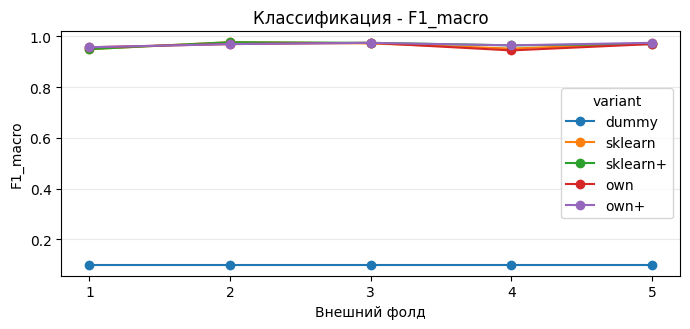


Регрессия - MAE
Эффект подбора sklearn: ухудшение, Delta=-2.4219, выигрышей 2/5, проигрышей 3/5
Своя реализация против исходной sklearn: ухудшение, Delta=-1.2352, выигрышей 1/5, проигрышей 4/5
Своя реализация против настроенной sklearn: улучшение, Delta=+0.0984, выигрышей 1/5, проигрышей 1/5
Эффект переноса настроек на свою реализацию: ухудшение, Delta=-1.0882, выигрышей 2/5, проигрышей 3/5


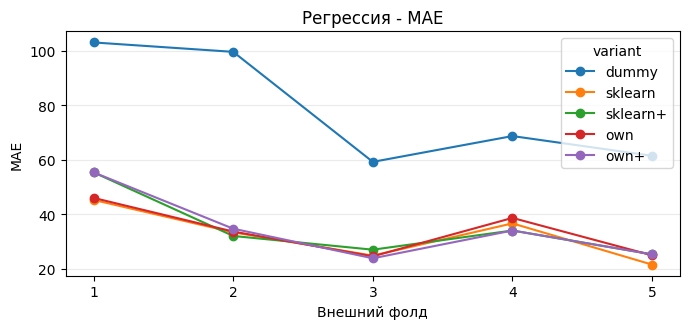

In [10]:
# считаем парные изменения метрики, чтобы сформулировать выводы по обеим задачам
comparisons = [
    ("sklearn+", "sklearn", "Эффект подбора sklearn"),
    ("own", "sklearn", "Своя реализация против исходной sklearn"),
    ("own+", "sklearn+", "Своя реализация против настроенной sklearn"),
    ("own+", "own", "Эффект переноса настроек на свою реализацию"),
]
for task in TASK_NAMES:
    metric = PRIMARY[task]
    values = results.loc[results["task"] == task].pivot(index="fold", columns="variant", values=metric)
    direction = 1 if task == "classification" else -1
    print(f"\n{TASK_NAMES[task]} - {metric}")
    for first, second, label in comparisons:
        gain = direction * (values[first] - values[second])
        mean = gain.mean()
        tendency = "улучшение" if mean > 1e-10 else "ухудшение" if mean < -1e-10 else "без изменений"
        wins = int((gain > 1e-10).sum())
        losses = int((gain < -1e-10).sum())
        print(f"{label}: {tendency}, Delta={mean:+.4f}, выигрышей {wins}/5, проигрышей {losses}/5")

    ax = values[VARIANTS].plot(marker="o", figsize=(7, 3.4), title=f"{TASK_NAMES[task]} - {metric}")
    ax.set(xlabel="Внешний фолд", ylabel=metric, xticks=values.index)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()